# Lesson 4 · Null models and permutation tests

**The central question:** the glomeruli DM1 and DM4 share a lot of KCs. Is that real **structure**, or a coincidence that random wiring would also produce?

The method has four steps:
1. compute the **observed statistic**: how many KCs DM1 and DM4 actually share;
2. build many randomised versions of the connection matrix (a **null model**);
3. compute the same statistic on each random matrix to get a **null distribution**;
4. see where the observed value falls in the null distribution, which gives a **p-value** and a **z-score**.

Run from top to bottom with **Shift + Enter**.

## Background: zooming in from the whole brain to DM1 and the KCs

```
fly brain (~140,000 neurons)
├── optic lobes (vision, more than half of all neurons)
├── central brain
│   ├── olfactory system  ← the part we study
│   │   ├── antennal lobe: first relay, organises odour signals
│   │   │     └── ~50 glomeruli; DM1 and DM4 are two of them
│   │   ├── mushroom body: learning and memory
│   │   │     └── ~2,600 KCs per side
│   │   └── lateral horn: innate odour responses
│   ├── central complex (navigation, locomotion)
│   └── ...
└── other (taste, mechanosensation, motor output, ...)
```

### What are DM1 and DM4?

**They are names of glomeruli, i.e. "channels" of the olfactory system.**

- The antenna has about 50 kinds of olfactory receptor, each sensitive to a class of molecules.
- All ORNs expressing the same receptor converge on the same glomerulus in the antennal lobe. So **one glomerulus = one receptor = one odour channel**.
- The names are just **positions**: D = dorsal, M = medial, so DM1 is "dorsomedial number 1". Likewise VA2 is ventral-anterior 2 and VM3 is ventral-medial 3.
- Each glomerulus has about 2–3 **PNs** that carry its signal to the mushroom body.

**Why DM1 and DM4 are interesting:** their receptors respond to **esters** such as ethyl acetate, fruity odours produced by fermenting fruit, so they are **food-related** channels. VM3 and VA2, which appear together with them in Lesson 5, are also thought to respond to food odours. (Check this against Zheng et al. 2022 before relying on it.)

### What are KCs?

**KCs are the principal cells of the mushroom body. They turn an odour into a code that can be learned.**

- Each KC takes input from about 4–5 glomerular channels (its dendritic *claws* grip PN boutons).
- So **one KC = one combination of a few channels**, and ~2,600 KCs give ~2,600 different combinations.
- An odour activates only about 5% of KCs. That set of active KCs is the odour's **identity tag** in the mushroom body.
- MBONs downstream read these tags. Reward or punishment signals from DANs modify the KC→MBON connections, and that is how the fly **learns** whether an odour predicts something good or bad.

### Putting it together: what "sharing KCs" means

```
DM1 channel ──PN──┐
                  ├──→ the same KC   (this KC "listens" to both DM1 and DM4)
DM4 channel ──PN──┘
```

- **If wiring were random**, each KC would pick a few channels at random, and some number of KCs would pick both DM1 and DM4 just by chance.
- **If the real number is much higher**, a group of KCs is preferentially reading the **DM1 + DM4 combination**.

**Possible biological meaning (a hypothesis to test later):** two food channels that are always read together might make the fly more sensitive to food odours, possibly at the cost of coding other odours less well.

## Step 0: build the KC × glomerulus binary matrix (provided)

As in Lesson 3 we use only right-calyx edges with `syn_count >= 5`. The differences:
- sister PNs of the same glomerulus are merged into one column, because they carry the same signal;
- the matrix is transposed: **rows = KCs, columns = glomeruli**, and each cell is 1 (connected) or 0 (not connected).

`B` is a pandas table (with labels, easy to look things up), and `Bm` is the same content as a numpy array (fast to compute with).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

edges = pd.read_parquet("../data/pn_kc_edges_all.parquet")
ann = pd.read_csv("../data/neuron_annotations.tsv", sep="\t", low_memory=False)

upn = ann[(ann.cell_class == "ALPN") & (ann.cell_sub_class == "uniglomerular")].copy()
upn["glom"] = upn.cell_type.str.split("_").str[0]

sub = edges[(edges.neuropil == "MB_CA_R") & (edges.syn_count >= 5)]
sub = sub.merge(upn[["root_id", "glom"]], left_on="pre_pt_root_id", right_on="root_id")

B = (sub.groupby(["post_pt_root_id", "glom"]).size().unstack(fill_value=0) > 0).astype(int)
Bm = B.values
glom_names = list(B.columns)
kc_class = (ann.set_index("root_id").cell_type.reindex(B.index)
               .str.extract(r"^(KCg|KCab|KCapbp|KCa'b')")[0]
               .replace({"KCa'b'": "KCapbp"}).values)
print("B shape (KC x glomerulus):", B.shape)
print("KC in-degree (mean):", Bm.sum(axis=1).mean().round(2))

B shape (KC x glomerulus): (2334, 55)
KC in-degree (mean): 4.14


## TODO 1: the observed statistic

A KC connected to both DM1 **and** DM4 counts as one co-input.

To do: count the KCs with both `B["DM1"] == 1` and `B["DM4"] == 1`, store the result as `obs` and print it.

Hint: both columns are 0/1, so their row-wise product is 1 only when both are 1; then `.sum()`. You can also use `&`.

In [2]:
# TODO 1
obs = (B["DM1"] * B["DM4"]).sum()
print("observed DM1-DM4 co-input:", obs)

observed DM1-DM4 co-input: 95


## TODO 2: first try a naive null model

The simplest randomisation is to **shuffle within each column**. Each glomerulus keeps the same number of KCs (its column sum, the glomerulus **degree**), but the number of inputs each KC receives (its row sum) changes.

The function is provided below. Your job:
1. call `naive_shuffle(Bm, rng)` to get `Bn`;
2. compare the **row-sum** (KC in-degree) distributions of `Bm` and `Bn`: print `np.bincount(...)` of `.sum(axis=1)` for each, or plot two histograms.

Think: most real KCs have 3–6 inputs. Is that still true after shuffling? If not, what goes wrong when you use it as a null model?

In [3]:
rng = np.random.default_rng(0)

def naive_shuffle(M, rng):
    out = M.copy()
    for j in range(M.shape[1]):
        out[:, j] = rng.permutation(M[:, j])   # shuffle within each column
    return out

In [4]:
# TODO 2
Bn = naive_shuffle(Bm, rng)
print("real  :", np.bincount(Bm.sum(axis=1)))
print("naive :", np.bincount(Bn.sum(axis=1)))
# The naive shuffle creates KCs with 0-1 inputs and KCs with many inputs: the in-degree distribution
# is destroyed, so it would compare the real brain with an impossible one.

real  : [  0 161 217 356 578 588 312  99  22   1]
naive : [ 34 158 302 447 442 390 281 158  72  32  12   5   0   1]


## TODO 3: implement one curveball swap

The **curveball algorithm** keeps both row sums and column sums fixed:

1. pick two KCs at random, say A and B;
2. leave the glomeruli they **share** untouched;
3. put the glomeruli that are **unique** to each into a pool, shuffle it and deal it back: A gets back as many as it had, B gets the rest.

Every KC keeps its number of inputs, and every glomerulus is still connected to the same number of KCs, just different ones.

In the skeleton below, each KC's inputs are a Python **set**. Fill in the three `___`:
- `only_a`: elements in `a` but not in `b`. Set difference is written `a - b`;
- `only_b`: the other way round;
- the new `rows[i]`: the shared part `common` plus the first `k` items of the pool. Set union is written `|`.

In [5]:
def curveball(M, n_swaps, rng):
    rows = [set(np.flatnonzero(r)) for r in M]   # the glomerulus indices each KC connects to
    n = len(rows)
    for _ in range(n_swaps):
        i, j = rng.choice(n, 2, replace=False)
        swap(rows, i, j, rng)
    out = np.zeros_like(M)
    for i, r in enumerate(rows):
        out[i, list(r)] = 1
    return out

In [6]:
# TODO 3
def swap(rows, i, j, rng):
    a, b = rows[i], rows[j]
    common = a & b
    only_a = a - b
    only_b = b - a
    pool = list(only_a) + list(only_b)
    rng.shuffle(pool)
    k = len(only_a)
    rows[i] = common | set(pool[:k])
    rows[j] = common | set(pool[k:])

## TODO 4: check that curveball really preserves the degrees

**Test an algorithm before you use it.** This is the most important habit in scientific programming.

To do:
1. `Bc = curveball(Bm, 5 * len(Bm), rng)`;
2. check that the row sums are identical: `np.array_equal(Bm.sum(axis=1), Bc.sum(axis=1))`;
3. check that the column sums are identical (`axis=0`);
4. check that the matrix really was shuffled: `(Bm != Bc).mean()` should be clearly above 0.

Move on only if all three checks pass.

In [7]:
# TODO 4
Bc = curveball(Bm, 5 * len(Bm), rng)
print("row sums same:", np.array_equal(Bm.sum(axis=1), Bc.sum(axis=1)))
print("col sums same:", np.array_equal(Bm.sum(axis=0), Bc.sum(axis=0)))
print("fraction changed:", (Bm != Bc).mean().round(4))

row sums same: True
col sums same: True
fraction changed: 0.1332


## TODO 5: null distribution, p-value and z-score

The next cell is provided: it generates 200 curveball-randomised matrices, computes the DM1–DM4 co-input on each, and stores the values in `null`. Each matrix continues shuffling from the previous one, which is faster. It takes about 20 seconds.

Run it, then in the TODO 5 cell:
1. plot a histogram of `null` and mark the observed value with `plt.axvline(obs, color="red")`;
2. compute the **p-value**: `p = (np.sum(null >= obs) + 1) / (len(null) + 1)`. The +1 avoids reporting p = 0: with 200 randomisations, the most you can say is p < 1/201;
3. compute the **z-score**: `(obs - null.mean()) / null.std()`.

In [8]:
iD1, iD4 = glom_names.index("DM1"), glom_names.index("DM4")
null = []
Bs = Bm.copy()
for k in range(200):
    Bs = curveball(Bs, len(Bm), rng)
    null.append((Bs[:, iD1] * Bs[:, iD4]).sum())
null = np.array(null)
print("null mean:", null.mean().round(1), " null sd:", null.std().round(1))

null mean: 42.7  null sd: 5.5


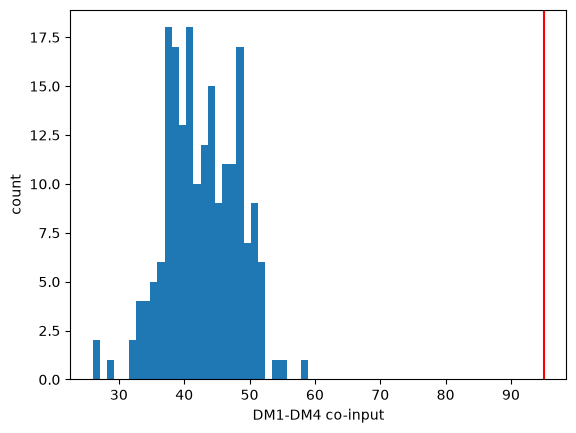

p = 0.005  z = 9.5


In [9]:
# TODO 5
plt.hist(null, bins=30)
plt.axvline(obs, color="red")
plt.xlabel("DM1-DM4 co-input")
plt.ylabel("count")
plt.show()

p = (np.sum(null >= obs) + 1) / (len(null) + 1)
z = (obs - null.mean()) / null.std()
print("p =", round(p, 4), " z =", round(z, 2))

## How to read the result

Compare your numbers with this reading (they vary slightly with the random seed):

- **null mean:** if wiring were random while keeping every KC's and every glomerulus's number of connections, this is how many KCs DM1 and DM4 would typically share.
- **observed / null mean:** how many times more sharing there is than chance (the **fold change**, a measure of effect size).
- **z:** how many standard deviations the observed value lies above the null mean. As a rough reference, z = 2 is usually called "significant"; z far above that is extreme.
- **p:** if **none** of the 200 randomisations reached the observed value, p = 1/201 ≈ 0.005. That is the **smallest** value 200 randomisations can give, so report it as **p < 0.005**, not p = 0.005.

**One-sentence conclusion:** DM1–DM4 co-convergence is far higher than expected under degree-preserving random wiring.

## TODO 6: a null model stratified by KC class

Different KC classes (γ, αβ, α'β') already prefer different glomeruli: you can see block structure if you sort the rows of `B` by class. If you shuffle all KCs together, the fact that "different classes get different inputs" is also counted as DM1–DM4 structure.

A stricter approach: **run curveball only within each class**. The function is provided.

To do: following the cell above TODO 5, generate 200 samples with `curveball_by_class`, store them as `null_cls`, compute the z-score and compare it with TODO 5.

Think: does the z-score go up or down after stratifying? Why is the stratified null "stricter"?

In [10]:
def curveball_by_class(M, classes, n_swaps_per_kc, rng):
    out = M.copy()
    for c in pd.unique(classes):
        idx = np.flatnonzero(classes == c)
        if len(idx) > 1:
            out[idx] = curveball(M[idx], n_swaps_per_kc * len(idx), rng)
    return out

In [11]:
# TODO 6
null_cls = []
Bs = Bm.copy()
for k in range(200):
    Bs = curveball_by_class(Bs, kc_class, 1, rng)
    null_cls.append((Bs[:, iD1] * Bs[:, iD4]).sum())
null_cls = np.array(null_cls)

z_cls = (obs - null_cls.mean()) / null_cls.std()
print("stratified null mean:", null_cls.mean().round(1), " z =", round(z_cls, 2))
# The null mean goes up and z goes down: part of the apparent structure was just KC-class preference.
# The stratified null keeps more of the real network's properties, so beating it is a stronger claim.

stratified null mean: 53.1  z = 7.31


## Self-test

1. Explain the **null hypothesis** and the **p-value** in one sentence each, using DM1–DM4 as the example.
2. Why is the naive shuffle a poor null model? What does curveball preserve?
3. About 56 glomeruli make about 1,500 pairs. If you tested every pair, roughly how many would have p < 0.05 even if wiring were completely random? What is this problem called (**multiple comparisons**)?
4. With 200 randomisations, what is the smallest p-value you can report? How would you report a smaller one?

**Model answers:**

1. Null hypothesis: KCs pick their glomeruli at random, given how many inputs each KC has and how many KCs each glomerulus reaches. p-value: the probability, under that null, of seeing DM1–DM4 sharing at least as many KCs as observed.
2. It changes the number of inputs per KC, producing KCs with 0 or 10 inputs that do not exist, so differences from it could reflect the wrong degree distribution rather than real pair structure. Curveball preserves both the row sums (inputs per KC) and the column sums (KCs per glomerulus).
3. About 5% of 1,500, i.e. ~75 pairs, by chance alone. This is the multiple-comparisons problem; it needs a correction (e.g. Bonferroni or false discovery rate) or an independent replication of the pairs you pick.
4. 1/201 ≈ 0.005. To report smaller p-values, run more randomisations (e.g. 10,000 gives a floor of ~1e-4); the z-score also conveys how extreme the value is.